# DE Sensitivity Check: Rare Genera at < 20% Prevalence (Recalled Genera)

With rare genera defined as < 10% seasonal prevalence and a 1% abundance cutoff, DESeq2 finds no significant genes (`transcriptomic_impact_of_dysbiosis_recalled_genera.ipynb`). This notebook checks whether a looser rare definition changes that:

- **Rare genera:** present in < 20% of seasonal plant samples. Genera seen only in circadian samples also count as rare.
- **Dysbiotic:** the abundance cutoff is chosen automatically so that about `target_n_dysbiotic` (45) transcriptome samples are called dysbiotic.
- **DESeq2:** same design (`~timepoint + High_rare_genera`) and gene filters as the main DE notebook.

It's standalone: it doesn't change `dysbiosis_calls_recalled_genera.csv` or anything the other notebooks read.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pydeseq2.default_inference
import pydeseq2.ds
import pydeseq2.dds
import Go_tools

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["svg.fonttype"] = "none"

In [2]:
###Define Thresholds
rare_genera_definition_threshold = 0.2  # prevalence in seasonal plant samples
target_n_dysbiotic = 45
expressed_gene_reads_threshold = 2000
number_of_samples_expressed_in_threshold = 21

In [3]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
metadata = metadata.drop(
    columns=[
        "arb.sort",
        "sample-id",
        "Ambiguous Unstranded",
        "Ambiguous Forward",
        "Multimapping",
        "Unmapped Over Mapped",
    ]
)
metadata["Date and Time"] = metadata["date"] + " " + metadata["time"]
luke_time_data_format = "%-m/%-d/%y %-H:%-M"
metadata["Date and Time"] = pd.to_datetime(
    metadata["Date and Time"], format=luke_time_data_format
)
raw_transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_for_norm.csv",
    index_col=0,
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
trimmed_raw_transcriptome = raw_transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426


## Rare genera (< 20% prevalence) and dysbiosis calls

In [4]:
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Sept_2026_recalled_genera/lic_16S_gen_rab_clean.csv"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]
genus_abundance_matrix = pd.pivot_table(
    plant_microbiome,
    values="Abundance",
    index="Sample",
    columns="Genus",
    aggfunc="sum",
    fill_value=0,
)
genus_abundance_matrix = (
    genus_abundance_matrix.div(genus_abundance_matrix.sum(axis=1), axis=0) * 100
)
seasonal_samples = plant_microbiome.loc[
    plant_microbiome["seascirc"] == "seasonal", "Sample"
].unique()
seasonal_prevalence = (genus_abundance_matrix.loc[seasonal_samples] > 0).mean()
rare_genera = seasonal_prevalence.index[
    seasonal_prevalence < rare_genera_definition_threshold
].tolist()
print(f"Rare genera (< {rare_genera_definition_threshold:.0%} prevalence): {len(rare_genera)}")
print(f"  of which < 10%: {(seasonal_prevalence[rare_genera] < 0.1).sum()}, 10-20%: {(seasonal_prevalence[rare_genera] >= 0.1).sum()}")

trimmed_metadata["rare_genera_total_abund"] = trimmed_metadata["sampID"].map(
    genus_abundance_matrix[rare_genera].sum(axis=1)
)
print("Transcriptomes without a microbiome profile (counted as not dysbiotic):", trimmed_metadata["rare_genera_total_abund"].isna().sum())
trimmed_metadata["rare_genera_total_abund"] = trimmed_metadata["rare_genera_total_abund"].fillna(0.0)

Rare genera (< 20% prevalence): 180
  of which < 10%: 160, 10-20%: 20
Transcriptomes without a microbiome profile (counted as not dysbiotic): 2


Rare genera abundance threshold: 1.827%
High_rare_genera
Low     381
High     45


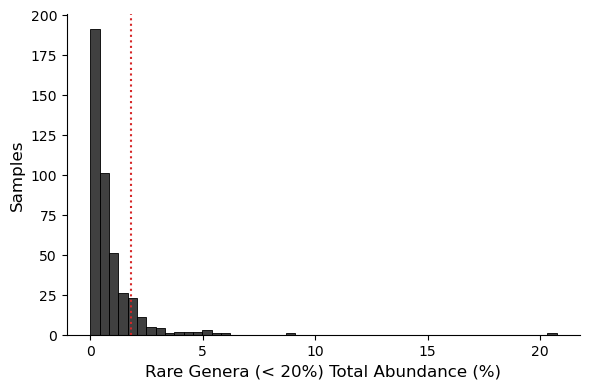

In [5]:
# Pick the cutoff halfway between the target-th and next-highest rare abundance,
# so that target_n_dysbiotic samples fall above it
sorted_abund = trimmed_metadata["rare_genera_total_abund"].sort_values(ascending=False).to_numpy()
rare_genera_abundance_threshold = round(
    (sorted_abund[target_n_dysbiotic - 1] + sorted_abund[target_n_dysbiotic]) / 2, 3
)
trimmed_metadata["High_rare_genera"] = np.where(
    trimmed_metadata["rare_genera_total_abund"] > rare_genera_abundance_threshold, "High", "Low"
)
print(f"Rare genera abundance threshold: {rare_genera_abundance_threshold}%")
print(trimmed_metadata["High_rare_genera"].value_counts().to_string())

fig, ax = plt.subplots(figsize=(6, 4))
fig.patch.set_facecolor("white")
sns.histplot(trimmed_metadata["rare_genera_total_abund"], bins=50, color="black", ax=ax)
ax.axvline(rare_genera_abundance_threshold, color="tab:red", linestyle="dotted")
plt.xlabel("Rare Genera (< 20%) Total Abundance (%)", fontsize=12)
plt.ylabel("Samples", fontsize=12)
sns.despine()
plt.tight_layout()

### How these calls compare

- **Main genus calls:** rare < 10% prevalence, > 1% abundance, from `dysbiosis_calls_recalled_genera.csv`.
- **Old species-level calls:** rebuilt as in the main DE notebook.

In [6]:
main_calls = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/dysbiosis_calls_recalled_genera.csv",
    index_col="sampID",
)["Dysbiosis Status"]
old_microbiome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Microbiome/lic2024_16S_rab.csv"
)
old_species_table = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/species_core_results.csv"
)
old_rare_abund = (
    old_microbiome.loc[
        old_microbiome["Species"].isin(
            old_species_table.loc[old_species_table["n_samples_present"] <= 37, "Species"]
        )
    ]
    .groupby("plantID")["AbundR100"]
    .sum()
)
calls_comparison = pd.DataFrame(
    {
        "Rare < 20% (this notebook)": trimmed_metadata["High_rare_genera"].map(
            {"High": "Dysbiotic", "Low": "Not Dysbiotic"}
        ),
        "Rare < 10% (main)": trimmed_metadata["sampID"].map(main_calls).fillna("Not Dysbiotic"),
        "Old species": np.where(
            trimmed_metadata["sampID"].map(old_rare_abund).fillna(0.0) > 9.5,
            "Dysbiotic",
            "Not Dysbiotic",
        ),
    },
    index=trimmed_metadata.index,
)
display(pd.crosstab(calls_comparison["Rare < 20% (this notebook)"], calls_comparison["Rare < 10% (main)"], margins=True))
display(pd.crosstab(calls_comparison["Rare < 20% (this notebook)"], calls_comparison["Old species"], margins=True))

Rare < 10% (main),Dysbiotic,Not Dysbiotic,All
Rare < 20% (this notebook),,,
Dysbiotic,38,7,45
Not Dysbiotic,18,363,381
All,56,370,426


Old species,Dysbiotic,Not Dysbiotic,All
Rare < 20% (this notebook),,,
Dysbiotic,24,21,45
Not Dysbiotic,26,355,381
All,50,376,426


## DESeq2

In [7]:
cleaned_raw_transcriptome = trimmed_raw_transcriptome.loc[
    :, trimmed_raw_transcriptome.sum() > expressed_gene_reads_threshold
]

cleaned_raw_transcriptome

,AT1G01010,AT1G01020,AT1G01030,AT1G01040,AT1G01050,AT1G01060,AT1G01070,AT1G01080,AT1G01090,AT1G01100,...,ArthCp081,Arthcp087,ArthCr091,ArthCr090,ArthCr089,ArthCt114,ArthCr088,ArthCp088,ArthCp083,ArthCp085
filename,,,,,,,,,,,,,,,,,,,,,
A2450525897_n01_LICRNA01_A01,19,5,26,84,154,118,9,31,314,1534,...,337,2650,0,17,659,0,45,1,15,3
A2450525897_n01_LICRNA01_B01,30,42,31,125,412,218,0,119,829,6287,...,675,7549,0,7,1392,9,125,1,7,11
A2450525897_n01_LICRNA01_C01,30,43,0,74,126,103,6,100,404,2864,...,261,3371,0,28,855,0,131,0,1,2
A2450525897_n01_LICRNA01_E01,19,27,22,41,135,89,3,56,299,3131,...,395,4594,6,10,542,0,44,0,3,5
A2450525897_n01_LICRNA01_F01,11,32,9,126,177,135,4,12,271,1782,...,371,2657,0,0,1402,0,235,0,8,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
A2534491401_n01_LICRNA05_D12,0,105,120,161,366,29,5,152,635,5043,...,541,7238,9,0,923,0,55,5,2,35
A2534491401_n01_LICRNA05_E12,0,23,26,166,298,381,19,198,1037,4265,...,1304,9335,0,8,868,44,89,16,50,23
A2534491401_n01_LICRNA05_F12,9,78,26,294,474,700,83,174,798,5139,...,786,4398,0,1,893,0,93,7,0,1


In [8]:
cleaned_raw_transcriptome = cleaned_raw_transcriptome.loc[
    :, (cleaned_raw_transcriptome > 1).sum() > number_of_samples_expressed_in_threshold
]

In [9]:
print("Genes kept for DESeq2:", cleaned_raw_transcriptome.shape[1])

Genes kept for DESeq2: 18032


In [10]:
transcriptome_for_large_deseq = cleaned_raw_transcriptome.loc[trimmed_metadata.index]
transcriptome_for_large_deseq
metadata_for_large_deseq = trimmed_metadata[["timepoint", "High_rare_genera"]]
metadata_for_large_deseq

,timepoint,High_rare_genera
filename,,
A2450525897_n01_LICRNA01_A01,t01,High
A2450525897_n01_LICRNA01_B01,t01,High
A2450525897_n01_LICRNA01_C01,t01,Low
A2450525897_n01_LICRNA01_E01,t01,Low
A2450525897_n01_LICRNA01_F01,t01,Low
...,...,...
A2534491401_n01_LICRNA05_D12,c1_t13,Low
A2534491401_n01_LICRNA05_E12,c1_t09,Low
A2534491401_n01_LICRNA05_F12,c1_t04,Low


In [11]:
inference = pydeseq2.default_inference.DefaultInference(n_cpus=6)
dds = pydeseq2.dds.DeseqDataSet(
    counts=transcriptome_for_large_deseq,
    metadata=metadata_for_large_deseq,
    design="~timepoint+High_rare_genera",
    refit_cooks=True,
    inference=inference,
    # n_cpus=8, # n_cpus can be specified here or in the inference object
)

In [12]:
dds.deseq2()

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...


... done in 0.28 seconds.



Fitting dispersions...


... done in 13.68 seconds.

Fitting dispersion trend curve...


... done in 0.50 seconds.

Fitting MAP dispersions...


... done in 18.62 seconds.

Fitting LFCs...


... done in 17.79 seconds.

Calculating cook's distance...


... done in 0.47 seconds.

Replacing 4 outlier genes.



Fitting dispersions...
... done in 0.02 seconds.

Fitting MAP dispersions...
... done in 0.02 seconds.

Fitting LFCs...
... done in 0.03 seconds.



In [13]:
ds_high_vs_low_rare_genera_all_samp = pydeseq2.ds.DeseqStats(
    dds, contrast=["High_rare_genera", "High", "Low"], inference=inference
)

In [14]:
ds_high_vs_low_rare_genera_all_samp.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: High_rare_genera High vs Low
             baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
AT1G01010    9.579553       -0.349892  0.301850 -1.159158  0.246392  0.848213
AT1G01020   52.852174        0.127444  0.111335  1.144684  0.252340  0.850849
AT1G01030   21.705831       -0.132908  0.175696 -0.756469  0.449368  0.919754
AT1G01040  117.400829       -0.072830  0.083792 -0.869174  0.384752  0.897290
AT1G01050  229.327898        0.026782  0.065196  0.410787  0.681228  0.971888
...               ...             ...       ...       ...       ...       ...
ArthCt114    4.266100       -0.967204  0.435660 -2.220090  0.026413  0.637828
ArthCr088   89.782102       -0.022514  0.139946 -0.160874  0.872193  0.988127
ArthCp088    8.744016       -0.191852  0.276541 -0.693755  0.487836  0.929191
ArthCp083   17.628219       -0.700904  0.236795 -2.959956  0.003077  0.434712
ArthCp085   11.225508       -0.069498  0.214803 -0.323541  0.746285  0.9819

... done in 1.72 seconds.



In [15]:
large_deseq_results = ds_high_vs_low_rare_genera_all_samp.results_df
large_deseq_padj_significant = large_deseq_results.loc[
    large_deseq_results["padj"] < 0.05
]
large_deseq_padj_significant
print("Significant genes (padj < 0.05):", len(large_deseq_padj_significant))

Significant genes (padj < 0.05): 1


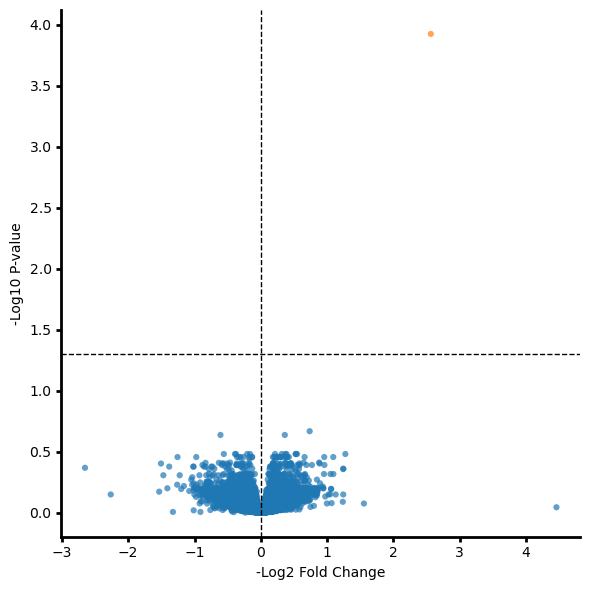

In [16]:
volcano_df = large_deseq_results[["log2FoldChange", "padj"]].copy()
volcano_df = volcano_df.replace([np.inf, -np.inf], np.nan).dropna()
volcano_df["neg_log10_padj"] = -np.log10(volcano_df["padj"].clip(lower=1e-300))
volcano_df["significant"] = volcano_df["padj"] < 0.05

fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(
    data=volcano_df,
    x="log2FoldChange",
    y="neg_log10_padj",
    hue="significant",
    alpha=0.7,
    s=20,
    linewidth=0,
    ax=ax,
    legend=True,
)
ax.axhline(-np.log10(0.05), linestyle="--", color="black", linewidth=1)
ax.axvline(0, linestyle="--", color="black", linewidth=1)
# ax.set_title("DE in dysbiotic samples")
ax.set_xlabel("-Log2 Fold Change")
ax.set_ylabel("-Log10 P-value")

ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)

ax.spines["top"].set_color("black")
ax.spines["top"].set_linewidth(0)

# ax2.spines["right"].set_color("black")
# ax2.spines["right"].set_linewidth(2)
# ax2.spines["top"].set_color("black")
# ax2.spines["top"].set_linewidth(0)
ax.tick_params(axis="both", width=2)
ax.get_legend().remove()
sns.despine()
plt.tight_layout()

In [17]:
sig_results = large_deseq_padj_significant.copy()
print(f"Upregulated: {(sig_results['log2FoldChange'] > 0).sum()}, downregulated: {(sig_results['log2FoldChange'] < 0).sum()}")
sig_results.sort_values("padj").head(40)

Upregulated: 1, downregulated: 0


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
AT5G19470,149.191647,2.562545,0.441787,5.800404,6.615541e-09,0.000119


In [18]:
large_deseq_gene_list = large_deseq_padj_significant.index.tolist()
pd.Series(large_deseq_gene_list).to_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/deseq_dysbiosis_gene_list_recalled_genera_rare20.csv",
    index=False,
    header=False,
)
large_deseq_results.to_csv("/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/deseq_dysbiosis_results_recalled_genera_rare20.csv")

# Overlap with the old species-level DE genes (59 genes, plates 1-5)
old_de_genes = set(
    pd.read_csv(
        "/Users/michael/Data/Luke_terrace_experiment/General_data/Junk_data/large_deseq_gene_list_all_plates.csv",
        header=None,
    )[0]
)
print(f"Old species-level DE genes: {len(old_de_genes)}")
print(f"Shared with this run: {len(old_de_genes & set(large_deseq_gene_list))}")
# How the old DE genes behave in this run
large_deseq_results.loc[large_deseq_results.index.isin(old_de_genes), ["log2FoldChange", "pvalue", "padj"]].describe()

Old species-level DE genes: 59
Shared with this run: 0


,log2FoldChange,pvalue,padj
count,59.000000,59.000000,59.000000
mean,0.006661,0.468955,0.885049
std,0.102537,0.293820,0.116073
min,-0.377162,0.009924,0.560663
25%,-0.031995,0.195626,0.822530
50%,0.023576,0.496835,0.930882
75%,0.063370,0.707541,0.976481
max,0.154149,0.990469,0.999378


## GO enrichment of significant genes (all namespaces, as in the original DE notebook)

In [19]:
go_term_matrix = pd.read_csv(
    "/Users/michael/Data/Reference_data/Arabdidopsis_go_matrix_from_tair_gaf.csv",
    index_col=0,
)
go_term_matrix

,GO:0000001,GO:0000009,GO:0000012,GO:0000014,GO:0000023,GO:0000024,GO:0000025,GO:0000026,GO:0000027,GO:0000028,...,GO:2001071,GO:2001080,GO:2001141,GO:2001142,GO:2001143,GO:2001147,GO:2001227,GO:2001280,GO:2001289,GO:2001294
GeneID,,,,,,,,,,,,,,,,,,,,,
AT1G01010,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AT1G01020,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AT1G01030,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AT1G01040,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AT1G01046,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AT5G67600,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AT5G67610,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AT5G67620,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [20]:
go_term_names = pd.read_csv(
    "/Users/michael/Data/Reference_data/goterm_names.csv", index_col=0
)
go_term_names

,x
GO:0000001,mitochondrion inheritance
GO:0000006,high-affinity zinc transmembrane transporter a...
GO:0000007,low-affinity zinc ion transmembrane transporte...
GO:0000009,"alpha-1,6-mannosyltransferase activity"
GO:0000010,heptaprenyl diphosphate synthase activity
...,...
GO:7770007,L-arginine conjugated cholate hydrolase activity
GO:7770008,L-histidine conjugated cholate hydrolase activity
GO:7770009,L-tryptophan conjugated cholate hydrolase acti...
GO:7770010,GTPBP3-MTO1 complex


In [21]:
background_genes_list = cleaned_raw_transcriptome.columns.tolist()

if len(large_deseq_gene_list) == 0:
    print("No significant DE genes: skipping GO enrichment.")
else:
    cont_tables_large = Go_tools.generate_contigency_tables(
        go_annotations=go_term_matrix,
        gene_list=large_deseq_gene_list,
        use_background_genes=True,
        background_genes=background_genes_list,
    )
    fishers_results_large = Go_tools.fishers_exact_on_contigency_tables(
        all_go_contigency_tables=cont_tables_large,
        original_GO_term_panda=go_term_matrix,
    )
    corrected_fishers_results_large = Go_tools.multi_hypothesis_correct_fishers_exact(
        fishers_results_large
    )
    named_large_fishers_results = corrected_fishers_results_large.merge(
        go_term_names, left_index=True, right_index=True, how="left"
    )
    display(named_large_fishers_results.sort_values("P_value").head(30))

,P_value,x
GO:0000001,1.0,mitochondrion inheritance
GO:0000009,1.0,"alpha-1,6-mannosyltransferase activity"
GO:0000012,1.0,single strand break repair
GO:0000014,1.0,single-stranded DNA endodeoxyribonuclease acti...
GO:0000023,1.0,maltose metabolic process
GO:0000024,1.0,maltose biosynthetic process
GO:0000025,1.0,maltose catabolic process
GO:0000026,1.0,"alpha-1,2-mannosyltransferase activity"
GO:0000027,1.0,ribosomal large subunit assembly
GO:0000028,1.0,ribosomal small subunit assembly
